Q1. Write a Python program to perform the following geometric transformations on an image:

    a. Translation
    b. Scaling
    c. Rotation
    d. Horizontal reflection
    e. Vertical reflection

Display the original and transformed images.

In [7]:
# modules import and path loading
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

image_path = "input2.jpg"
if not os.path.isfile(image_path):
    image_path = os.path.join("..", "input2.jpg")

if not os.path.isfile(image_path):
    raise FileNotFoundError("Image file not found. Check the path and filename.")

image_bgr = cv2.imread(image_path)
if image_bgr is None:
    raise ValueError(f"OpenCV could not read the image file: {os.path.abspath(image_path)}")

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width = image.shape[:2]


def show_transformation(title, transformed):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[1].imshow(transformed)
    axes[1].set_title(title)
    for axis in axes:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Loaded {os.path.abspath(image_path)} ({width} x {height})")
#print("cell working")

Loaded c:\Programming file\VS coder file\Python programs\Image processing\input2.jpg (500 x 560)


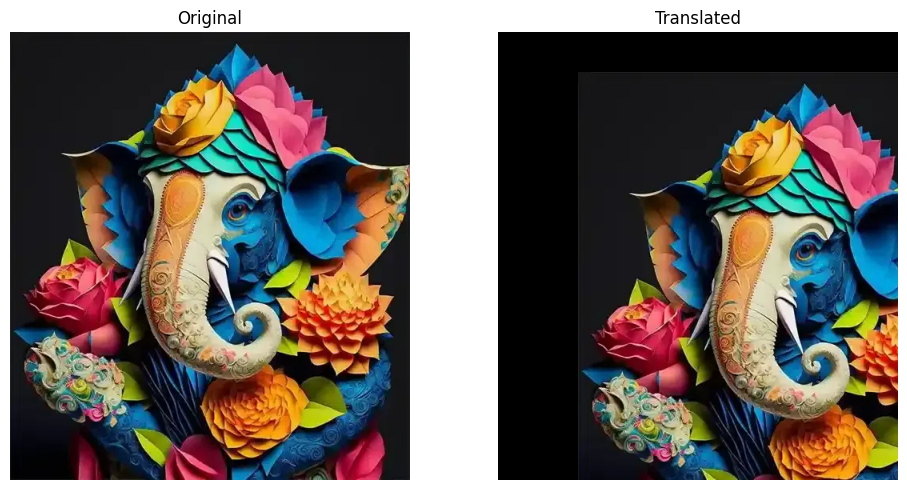

In [8]:
# a. Translation: move the image 100 pixels right and 50 pixels down.
tx, ty = 100, 50
translation_matrix = np.float32([[1, 0, tx], [0, 1, ty]])
translated = cv2.warpAffine(image, translation_matrix, (width, height))
show_transformation("Translated", translated)

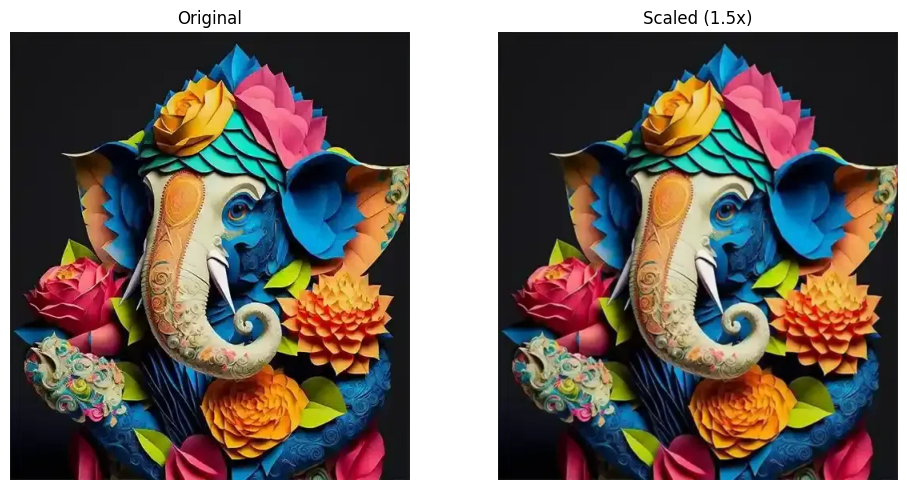

In [9]:
# b. Scaling: enlarge the image by 1.5 times in both directions.
scale_x, scale_y = 1.5, 1.5
scaled = cv2.resize(
    image,
    None,
    fx=scale_x,
    fy=scale_y,
    interpolation=cv2.INTER_LINEAR,
)
show_transformation("Scaled (1.5x)", scaled)

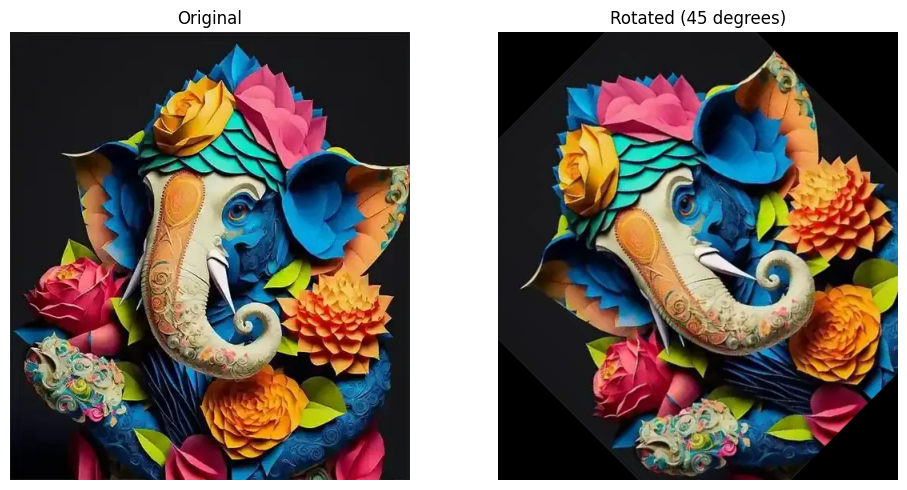

In [10]:
# c. Rotation: rotate the image 45 degrees counterclockwise.
angle = 45
center = (width / 2, height / 2)
rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
rotated = cv2.warpAffine(image, rotation_matrix, (width, height))
show_transformation("Rotated (45 degrees)", rotated)

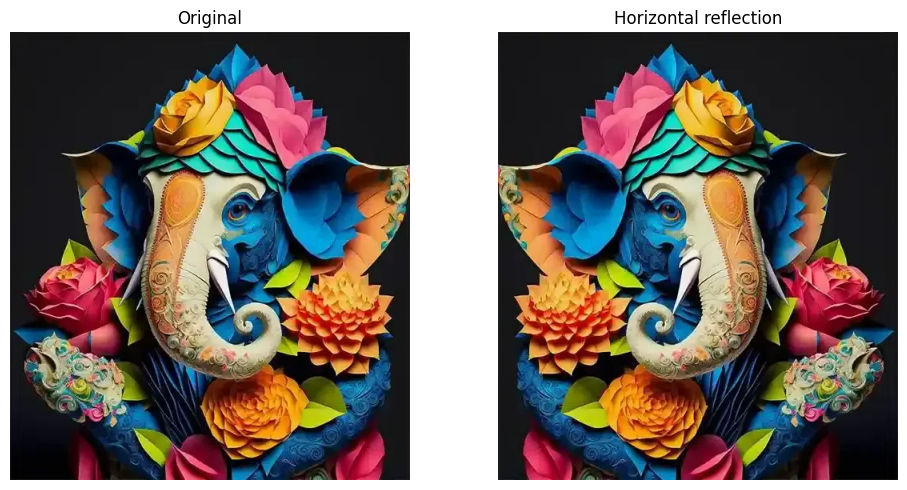

In [11]:
# d. Horizontal reflection: mirror left to right.
horizontal_reflection = cv2.flip(image, 1)
show_transformation("Horizontal reflection", horizontal_reflection)

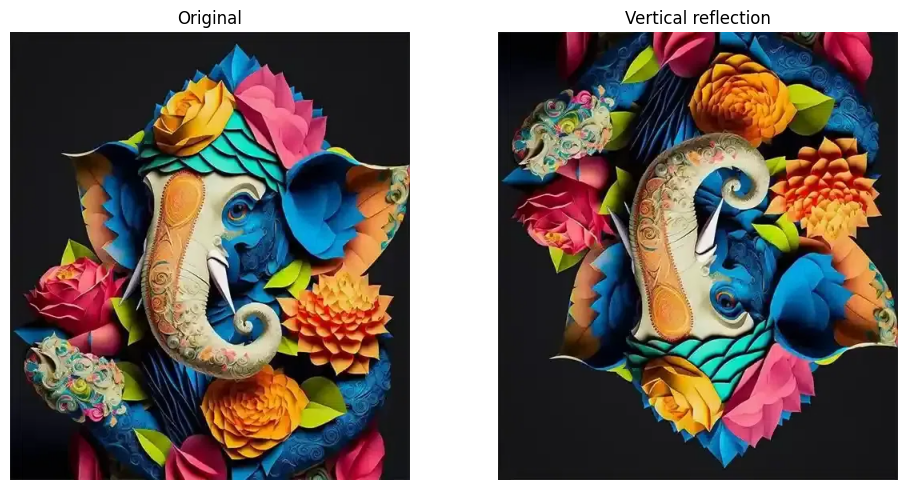

In [12]:
# e. Vertical reflection: flip top to bottom.
vertical_reflection = cv2.flip(image, 0)
show_transformation("Vertical reflection", vertical_reflection)